# Plot Four-Series Scaling From Sampling Checkpoints

This notebook reads both `original` and `log` sampling checkpoints from `data/` and overlays four series in each panel:

- original expected
- original empirical
- log expected
- log empirical

Color encodes the method: original is blue and log is red. Marker and line style encode the statistic: expected uses circle markers with dashed lines, while empirical uses diamond markers with solid lines and error bars.


In [1]:
import json
import math
from collections import defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np

%config InlineBackend.figure_format = 'retina'
plt.rcParams['font.family'] = 'Times New Roman'
plt.rcParams.update({'font.size': 17})
plt.rcParams['text.usetex'] = True

SAVE_PDF = True
FIG_DIR = Path('figures')
FIG_DIR.mkdir(parents=True, exist_ok=True)
DATA_DIR = Path('data')
CHANNEL = 1
FIGURE_TAG = 'channel_' if CHANNEL else 'operator_'
FAMILY_LABEL = 'channel' if CHANNEL else 'operator'
RESULT_PATTERNS = ['NCC_channel_*_sampling_r_*.json'] if CHANNEL else ['NCC_original_sampling_r_*.json', 'NCC_log_sampling_r_*.json']

BASELINE = {
    'N': 8,
    'T': 2.0,
    'epsilon': 0.001,
}
EPSILON_TARGETS = [0.1, 0.04, 0.02, 0.01, 0.005, 0.0025, 0.001]
SWEEP_TARGETS = {
    'N': list(range(4, 10)),
    'T': [0.2, 0.4, 0.6, 0.8, 1.0, 2.0],
    'inv_epsilon': [float(1.0 / eps) for eps in EPSILON_TARGETS],
}

MODE_STYLE = {
    'original': {'label': 'original', 'color': '#1f77b4'},
    'log': {'label': 'log', 'color': '#d62728'},
}
STAT_STYLE = {
    'expected': {'label': 'expected', 'marker': 'o', 'linestyle': '--', 'linewidth': 1.8, 'markersize': 6},
    'empirical': {'label': 'empirical', 'marker': 'D', 'linestyle': '-', 'linewidth': 1.8, 'markersize': 5},
}

OVERHEAD_FLOOR_EXPECTED = True
OVERHEAD_RMIN_PATH = Path('pauli_sampling_overhead_rmin_N8.csv')
OVERHEAD_RMIN_N_SWEEP_PATH = Path('pauli_sampling_overhead_rmin_N_sweep_T2.csv')

# Pauli-sampling overhead floors from pauli_sampling_overhead_bound.md.
# The T and 1/epsilon sweeps use the N=8 table; the N sweep uses the
# N-dependent table at fixed T=2.0.
def load_overhead_rmin_table(path):
    table = np.genfromtxt(path, delimiter=',', names=True)
    table = np.atleast_1d(table)
    rows = {}
    for row in table:
        rows[round(float(row['T']), 12)] = {
            'original_operator': float(row['original_operator']),
            'original_channel': float(row['original_channel']),
            'log_operator': float(row['log_operator_s6']),
            'log_channel': float(row['log_channel_s4']),
        }
    return rows


OVERHEAD_RMIN_BY_T = load_overhead_rmin_table(OVERHEAD_RMIN_PATH)


def load_overhead_n_sweep_table(path):
    table = np.genfromtxt(path, delimiter=',', names=True)
    table = np.atleast_1d(table)
    rows = {}
    for row in table:
        rows[int(round(float(row['N'])))] = {
            'original_operator': float(row['original_operator']),
            'log_operator': float(row['log_operator_s6']),
            'original_channel': float(row['original_channel']),
            'log_channel': float(row['log_channel_s4']),
        }
    return rows


OVERHEAD_RMIN_BY_N = load_overhead_n_sweep_table(OVERHEAD_RMIN_N_SWEEP_PATH)


def overhead_floor_key(mode):
    if mode == 'original':
        return 'original_channel' if CHANNEL else 'original_operator'
    if mode == 'log':
        return 'log_channel' if CHANNEL else 'log_operator'
    raise ValueError(mode)


def lookup_overhead_rmin(T, mode):
    for table_T, row in OVERHEAD_RMIN_BY_T.items():
        if math.isclose(float(T), table_T, rel_tol=0.0, abs_tol=1e-12):
            return row[overhead_floor_key(mode)]
    available = ', '.join(f'{T:g}' for T in sorted(OVERHEAD_RMIN_BY_T))
    raise ValueError(f'No Pauli-sampling overhead r_min for T={T}; available T values: {available}')


def lookup_overhead_n_rmin(N, mode):
    n_key = int(round(float(N)))
    row = OVERHEAD_RMIN_BY_N.get(n_key)
    if row is None:
        return 0.0
    return row[overhead_floor_key(mode)]


def expected_overhead_floor(axis_key, x_value, mode):
    if not OVERHEAD_FLOOR_EXPECTED:
        return 0.0
    if axis_key == 'N':
        return float(lookup_overhead_n_rmin(float(x_value), mode))
    if axis_key == 'T':
        return float(lookup_overhead_rmin(float(x_value), mode))
    if axis_key == 'inv_epsilon':
        return float(lookup_overhead_rmin(float(BASELINE['T']), mode))
    return 0.0

def infer_mode(payload, path):
    mode = payload.get('mode')
    if mode in MODE_STYLE:
        return mode
    script = payload.get('script', '')
    stem = path.stem.lower()
    if 'original' in script.lower() or 'original' in stem:
        return 'original'
    if 'log' in script.lower() or 'log' in stem:
        return 'log'
    return None


def ci_bounds(values):
    values = np.asarray(values, dtype=float)
    if values.size == 0:
        return float('nan'), float('nan'), float('nan')
    mean = float(values.mean())
    if values.size == 1:
        return mean, mean, mean
    std = float(values.std(ddof=1))
    half = 1.96 * std / math.sqrt(values.size)
    return mean, mean - half, mean + half


def format_tick_labels(values):
    labels = []
    for value in np.array(values, dtype=float):
        if math.isclose(value, round(value), abs_tol=1e-12):
            labels.append(str(int(round(value))))
        else:
            labels.append(f'{value:.2f}'.rstrip('0').rstrip('.'))
    return labels


Y_TICKS = np.array([20.0, 40.0, 100.0, 200.0, 400.0, 600.0], dtype=float)


def configure_log_ticks(ax, x_values, y_values, rotate_x=False):
    x_values = np.array(sorted(set(np.asarray(x_values, dtype=float))), dtype=float)
    y_values = np.array(sorted(set(np.asarray(y_values, dtype=float))), dtype=float)
    if x_values.size:
        ax.xaxis.set_major_locator(mticker.FixedLocator(x_values))
        ax.xaxis.set_major_formatter(mticker.FixedFormatter(format_tick_labels(x_values)))
    ax.yaxis.set_major_locator(mticker.FixedLocator(Y_TICKS))
    ax.yaxis.set_major_formatter(mticker.FixedFormatter(format_tick_labels(Y_TICKS)))
    ax.xaxis.set_minor_formatter(mticker.NullFormatter())
    ax.yaxis.set_minor_formatter(mticker.NullFormatter())
    if rotate_x:
        ax.tick_params(axis='x', labelrotation=20)


def apply_center_limits(ax, x_values, y_values, y_low=None, y_high=None):
    x_values = np.asarray(x_values, dtype=float)
    y_values = np.asarray(y_values, dtype=float)
    y_low = y_values if y_low is None else np.asarray(y_low, dtype=float)
    y_high = y_values if y_high is None else np.asarray(y_high, dtype=float)

    if x_values.size == 1:
        ax.set_xlim(float(x_values[0] / 1.2), float(x_values[0] * 1.2))
    else:
        ax.set_xlim(float(np.min(x_values) / 1.08), float(np.max(x_values) * 1.08))

    y_min = float(np.nanmin(y_low))
    y_max = float(np.nanmax(y_high))
    if y_values.size == 1:
        ax.set_ylim(y_min / 1.08, y_max * 1.08)
    else:
        ax.set_ylim(y_min / 1.08, y_max * 1.08)


def plot_missing(ax, title, xlabel):
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.text(0.5, 0.5, 'data not collected', ha='center', va='center', fontsize=18, transform=ax.transAxes)
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_alpha(0.3)


def parse_checkpoint(path):
    if 'smoke' in path.stem.lower():
        return None
    payload = json.loads(path.read_text())
    mode = infer_mode(payload, path)
    if mode is None:
        return None
    params = payload.get('params', {})
    sampled = np.asarray(payload.get('sampled_r_mins', []), dtype=float)
    expected = np.asarray(payload.get('expected_r_mins', []), dtype=float)
    expected = expected[expected >= 0]
    sampled_mean, sampled_low, sampled_high = ci_bounds(sampled)
    expected_mean = float(expected.mean()) if expected.size else float('nan')
    return {
        'path': path,
        'mode': mode,
        'N': int(params['N']),
        'T': float(params['T']),
        'epsilon': float(params['epsilon']),
        'inv_epsilon': float(1.0 / float(params['epsilon'])),
        'trials': int(params['trials']),
        'repeats': int(params['repeats']),
        'sampled_mean': sampled_mean,
        'sampled_low': sampled_low,
        'sampled_high': sampled_high,
        'expected_mean': expected_mean,
    }


records = []
for pattern in RESULT_PATTERNS:
    for path in sorted(DATA_DIR.rglob(pattern)):
        if 'smoke' in path.parts:
            continue
        record = parse_checkpoint(path)
        if record is not None:
            records.append(record)

if not records:
    raise RuntimeError(f'No matching {FAMILY_LABEL} original/log checkpoint json files found under data/.')


def choose_best(records_for_same_point):
    return max(records_for_same_point, key=lambda item: (item['repeats'], item['trials']))


def collect_series(axis_key):
    grouped = defaultdict(list)
    for record in records:
        if axis_key == 'N':
            if not math.isclose(record['T'], BASELINE['T'], rel_tol=0.0, abs_tol=1e-12) or not math.isclose(record['epsilon'], BASELINE['epsilon'], rel_tol=0.0, abs_tol=1e-12):
                continue
            x_value = record['N']
        elif axis_key == 'T':
            if record['N'] != BASELINE['N'] or not math.isclose(record['epsilon'], BASELINE['epsilon'], rel_tol=0.0, abs_tol=1e-12):
                continue
            x_value = record['T']
        elif axis_key == 'inv_epsilon':
            if record['N'] != BASELINE['N'] or not math.isclose(record['T'], BASELINE['T'], rel_tol=0.0, abs_tol=1e-12):
                continue
            x_value = record['inv_epsilon']
        else:
            raise ValueError(axis_key)
        grouped[(record['mode'], x_value)].append(record)

    series = defaultdict(list)
    for mode in MODE_STYLE:
        for target in SWEEP_TARGETS[axis_key]:
            items = grouped.get((mode, target), [])
            if items:
                series[mode].append((target, choose_best(items)))
    return series


series_by_axis = {axis: collect_series(axis) for axis in ('N', 'T', 'inv_epsilon')}

print('loaded checkpoints:', len(records))
for axis in ('N', 'T', 'inv_epsilon'):
    for mode in MODE_STYLE:
        print(axis, mode, [x for x, _ in series_by_axis[axis].get(mode, [])])



loaded checkpoints: 20
N original [4, 5, 6, 7]
N log [4, 5, 6, 7]
T original [0.2, 0.4, 0.6, 0.8, 1.0]
T log [0.2, 0.4, 0.6, 0.8, 1.0]
inv_epsilon original [10.0]
inv_epsilon log [10.0]


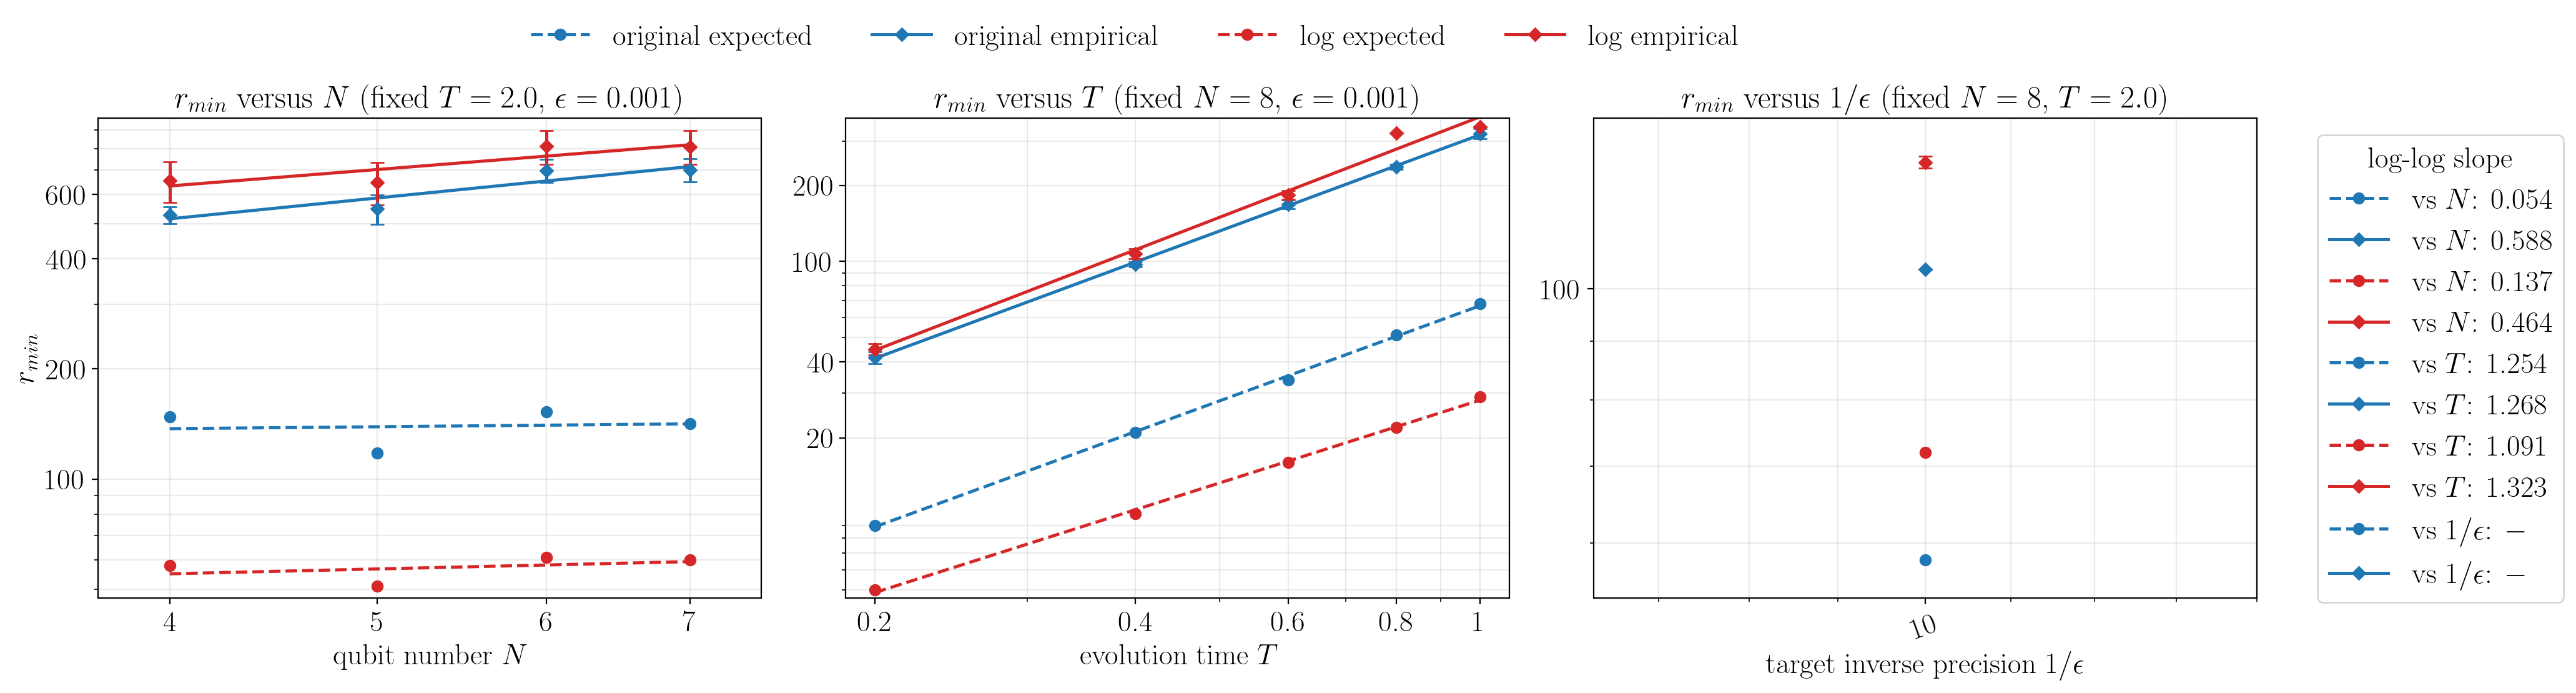

In [2]:
plt.close('all')

from matplotlib.lines import Line2D


def use_fit_line(axis_key, mode):
    if axis_key in ('N', 'T'):
        return True
    if axis_key == 'inv_epsilon' and mode == 'original':
        return True
    return False


def fit_power_law(xs, ys):
    xs = np.asarray(xs, dtype=float)
    ys = np.asarray(ys, dtype=float)
    mask = (xs > 0) & (ys > 0) & np.isfinite(xs) & np.isfinite(ys)
    if np.count_nonzero(mask) < 2:
        return float('nan'), xs[mask], ys[mask]
    log_x = np.log(xs[mask])
    log_y = np.log(ys[mask])
    slope, intercept = np.polyfit(log_x, log_y, deg=1)
    x_fit = np.geomspace(float(np.min(xs[mask])), float(np.max(xs[mask])), 200)
    y_fit = np.exp(intercept) * x_fit**slope
    return float(slope), x_fit, y_fit


def slope_label(axis_slope_label, slope):
    if not np.isfinite(slope):
        return rf'vs {axis_slope_label}: $-$'
    return rf'vs {axis_slope_label}: {slope:.3f}'


def make_slope_handle(mode_style, style):
    return Line2D(
        [0],
        [0],
        color=mode_style['color'],
        marker=style['marker'],
        linestyle=style['linestyle'],
        linewidth=style['linewidth'],
        markersize=style['markersize'],
    )


def draw_expected(ax, xs, ys, mode_style, style, fit_enabled):
    if fit_enabled:
        ax.plot(
            xs,
            ys,
            marker=style['marker'],
            linestyle='None',
            markersize=style['markersize'],
            color=mode_style['color'],
        )
        slope, x_fit, y_fit = fit_power_law(xs, ys)
        ax.plot(
            x_fit,
            y_fit,
            linestyle=style['linestyle'],
            linewidth=style['linewidth'],
            color=mode_style['color'],
        )
        return slope
    ax.plot(
        xs,
        ys,
        marker=style['marker'],
        linestyle=style['linestyle'],
        linewidth=style['linewidth'],
        markersize=style['markersize'],
        color=mode_style['color'],
    )
    return None


def draw_empirical(ax, xs, means, yerr, mode_style, style, fit_enabled):
    line_style = 'None' if fit_enabled else style['linestyle']
    ax.errorbar(
        xs,
        means,
        yerr=yerr,
        marker=style['marker'],
        linestyle=line_style,
        linewidth=style['linewidth'],
        markersize=style['markersize'],
        color=mode_style['color'],
        capsize=4,
    )
    if fit_enabled:
        slope, x_fit, y_fit = fit_power_law(xs, means)
        ax.plot(
            x_fit,
            y_fit,
            linestyle=style['linestyle'],
            linewidth=style['linewidth'],
            color=mode_style['color'],
        )
        return slope
    return None


def plot_four_series_panel(ax, axis_key, axis_slope_label, xlabel, title, slope_entries):
    ax.set_xscale('log')
    ax.set_yscale('log')
    x_values = []
    y_values = []
    y_lows = []
    y_highs = []

    for mode, mode_style in MODE_STYLE.items():
        points = series_by_axis[axis_key].get(mode, [])
        if not points:
            continue

        xs = np.array([x for x, _ in points], dtype=float)
        expected = np.array([item['expected_mean'] for _, item in points], dtype=float)
        if axis_key in ('N', 'T', 'inv_epsilon'):
            floors = np.array([expected_overhead_floor(axis_key, x, mode) for x in xs], dtype=float)
            expected = np.maximum(expected, floors)
        empirical = np.array([item['sampled_mean'] for _, item in points], dtype=float)
        lows = np.array([item['sampled_low'] for _, item in points], dtype=float)
        highs = np.array([item['sampled_high'] for _, item in points], dtype=float)
        yerr = np.vstack([empirical - lows, highs - empirical])

        fit_enabled = use_fit_line(axis_key, mode)
        expected_slope = draw_expected(ax, xs, expected, mode_style, STAT_STYLE['expected'], fit_enabled)
        if expected_slope is not None:
            slope_entries.append((
                make_slope_handle(mode_style, STAT_STYLE['expected']),
                slope_label(axis_slope_label, expected_slope),
            ))
        empirical_slope = draw_empirical(ax, xs, empirical, yerr, mode_style, STAT_STYLE['empirical'], fit_enabled)
        if empirical_slope is not None:
            slope_entries.append((
                make_slope_handle(mode_style, STAT_STYLE['empirical']),
                slope_label(axis_slope_label, empirical_slope),
            ))

        x_values.extend(xs.tolist())
        y_values.extend(expected.tolist())
        y_values.extend(empirical.tolist())
        y_lows.extend(expected.tolist())
        y_lows.extend(lows.tolist())
        y_highs.extend(expected.tolist())
        y_highs.extend(highs.tolist())

    if not x_values:
        plot_missing(ax, title, xlabel)
        return

    apply_center_limits(ax, x_values, y_values, y_low=y_lows, y_high=y_highs)
    configure_log_ticks(ax, x_values, y_values, rotate_x=(axis_key == 'inv_epsilon'))
    ax.set_xlabel(xlabel)
    ax.set_title(title, fontsize=18)
    ax.grid(True, which='both', alpha=0.25)


slope_entries = []
fig, axes = plt.subplots(1, 3, figsize=(22, 5.5))
plot_four_series_panel(
    axes[0],
    'N',
    r'$N$',
    r'qubit number $N$',
    rf'$r_{{min}}$ versus $N$ (fixed $T={BASELINE["T"]}$, $\epsilon={BASELINE["epsilon"]}$)',
    slope_entries,
)
plot_four_series_panel(
    axes[1],
    'T',
    r'$T$',
    r'evolution time $T$',
    rf'$r_{{min}}$ versus $T$ (fixed $N={BASELINE["N"]}$, $\epsilon={BASELINE["epsilon"]}$)',
    slope_entries,
)
plot_four_series_panel(
    axes[2],
    'inv_epsilon',
    r'$1/\epsilon$',
    r'target inverse precision $1/\epsilon$',
    rf'$r_{{min}}$ versus $1/\epsilon$ (fixed $N={BASELINE["N"]}$, $T={BASELINE["T"]}$)',
    slope_entries,
)
axes[0].set_ylabel(r'$r_{min}$')
for ax in axes[1:]:
    ax.set_ylabel('')

semantic_handles = []
semantic_labels = []
for mode, mode_style in MODE_STYLE.items():
    for stat, stat_style in STAT_STYLE.items():
        semantic_handles.append(
            Line2D(
                [0],
                [0],
                color=mode_style['color'],
                marker=stat_style['marker'],
                linestyle=stat_style['linestyle'],
                linewidth=stat_style['linewidth'],
                markersize=stat_style['markersize'],
            )
        )
        semantic_labels.append(f'{mode_style["label"]} {stat_style["label"]}')
fig.legend(semantic_handles, semantic_labels, loc='upper center', ncol=4, frameon=False, bbox_to_anchor=(0.42, 1.04))

plot_right = 0.84
right_space = 0.005
if slope_entries:
    slope_handles, slope_labels = zip(*slope_entries)
    fig.legend(
        slope_handles,
        slope_labels,
        title='log-log slope',
        loc='center left',
        bbox_to_anchor=(plot_right + right_space, 0.5),
        frameon=True,
        fontsize=17,
        title_fontsize=17,
    )
fig.tight_layout(rect=[0, 0, plot_right, 0.96])
if SAVE_PDF:
    fig.savefig(FIG_DIR / f'scaling_{FIGURE_TAG}four_series.pdf', bbox_inches='tight')
plt.show()
plt.close(fig)


